# Exercise 6
**Veikka Immonen**

In [ ]:
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from collections.abc import Iterable
import torch

from matern_spde import MaternFDMSPDESampler

import scienceplots
plt.style.use(['science'])

## Matérn sampler via SPDE approximation

## Space-varying kernel width optimization

### Simulation
The model:
$$
y(t) = [K * x](t) = \int_T K(t-t'; \theta(t))x(t')~\text{d}t' + \epsilon(t).
$$
Let $x_i: [0, 1] \rightarrow \mathbb{R}$ be periodic s.t. $x_i(t+1) = x_i(t)$, same with the kernel $K(\cdot, \theta(t))$. Data is generated as
* $\bm{x}_i \sim \text{Matérn field with } (\nu, \ell, \tau) = (2.5, 0.05, 1.0), ~ i=1,...,m$, with process mean $\mu_{x} = 3.0$
* $\theta(t) = 0.01 + 0.09\left(1-\left(2t-1\right)^{2}\right)$
* $\bm{y}_i = \bm{K}_{\bm{\theta}} \bm{x}_i + \bm{\epsilon}_i, ~ \bm{\epsilon}_i \sim \mathcal{N}(\bm{0}, \sigma^2\bm{I}), ~ i = 1,...,m$
* $\sigma = 0.1$
* $\dim(\bm{x}_i) = \dim(\bm{\theta}) = 400$
* $\dim(\bm{y}_i) = 50$
* $m=20$ 

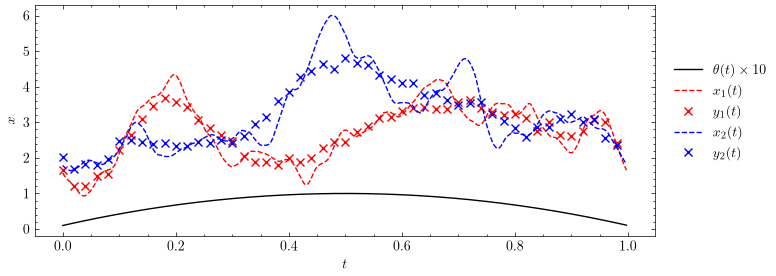

In [49]:
n_full = 400
n_data = 50
m = 20

state_matern_param = {"nu": 2.5, "ell": 0.05, "sigma": 1.0}
state_mu = 3.0

sigma_noise = 0.1

def boxcar_kernel(t1, t2, theta):
    n, m = map(len, (t1, t2))
    step = n // m
    dt = (t1[1] - t1[0]).item()
    if isinstance(theta, Iterable):
        assert len(theta) == len(t1)
        c = np.where(abs(theta) < dt, 1.0, dt / (2 * theta))
    else:
        c = 1.0 if abs(theta) < dt else dt / (2 * theta)
        c = np.full_like(t1, c)
        theta = np.full_like(t1, theta)
    k = sp.lil_array((m, n))
    for i in range(m):
        for j in range(n):
            d = abs(t2[i] - t1[j])
            d_periodic = min(d, 1.0 - d)
            if d_periodic <= theta[i * step]: k[i, j] = c[i * step]
    k /= k.sum(axis=1)[:, None]
    return k.tocsc()

sampler_state = MaternFDMSPDESampler(((0, 1),), (n_full,), (True,), pad=0, **state_matern_param)

t_full = np.linspace(0, 1, n_full, endpoint=False)
t_data = np.linspace(0, 1, n_data, endpoint=False)

np.random.seed(0)
X = sampler_state(m) + state_mu
theta_true = 0.01 + 0.09 * (1 - (2*t_full - 1)**2)

K_true = boxcar_kernel(t_full, t_data, theta_true)

Y = X @ K_true.T + sigma_noise * np.random.randn(m, n_data)

# plot
_, ax = plt.subplots(figsize=(8, 3))
ax.set_xlabel("$t$")
ax.set_ylabel("$x$")

ax.plot(t_full, theta_true*10, 'k', label=r"$\theta(t) \times 10$")
ax.plot(t_full, X[0], 'r--', label=r"$x_1(t)$")
ax.plot(t_data, Y[0], 'rx', label=r"$y_1(t)$")
ax.plot(t_full, X[1], 'b--', label=r"$x_2(t)$")
ax.plot(t_data, Y[1], 'bx', label=r"$y_2(t)$")
ax.legend(bbox_to_anchor=(1.2, 0.8))

plt.savefig("data_1.pdf")
plt.show()

In [48]:
data_dict = {
    "theta": torch.from_numpy(theta_true),
    "X": torch.from_numpy(X),
    "Y": torch.from_numpy(Y)
}
torch.save(data_dict, "data.pt")

### Neural network

The neural network $\theta(t) \approx \Psi(t; \{\bm{W}_i,\bm{b}_i\}_{i=1}^L)$ computes for each layer $i$:
* $\bm{z}_i = (\bm{W}_i \bm{x}_{i-1} + \bm{b}_i)$
* $\bm{x}_i = \tanh(\bm{z_i})$,

execpt from the last layer, where $\bm{x}_L$ is not computed and $\bm{z}_L$ is considered as output.